# Los seis choques de Basilea paso a paso: el escalar 0,417, el empinamiento de +25,4 pb y el aplanamiento de -1,6 pb

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el cuaderno 01 de este tema (las 19 bandas, la brecha y el EVE)
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este cuaderno puedes:

- construir cada una de las seis formas de choque estándar (paralelo al alza y a la baja, corto al alza y a la baja, empinamiento, aplanamiento) desde sus dos escalares y sus tamaños, e imprimir cada intermedio;
- reproducir con el motor el ejemplo resuelto del estándar (0,417, +41,7 pb, +25,4 pb y -1,6 pb a 3,5 años) y leer la prueba de valores de referencia que lo guarda;
- decir de dónde vienen los tamaños (las tablas de 2016 y de 2024, y la tabla del regulador chileno) y qué hace el motor cuando una moneda no tiene tamaño;
- aplicar un piso posterior al choque y decir en qué bandas actúa, con el piso en cero y con el piso dependiente del plazo de la Unión Europea;
- comparar cada forma con la versionada, nombrando la versión del motor que la calculó.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.irrbb import shocks, slotting
from riskvalidation.validation import irrbb as rv_irrbb

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
matplotlib 3.11.2


## Datos

Tres documentos versionados alimentan el cuaderno:

- `data/derived/C14/vd-2022-q2.json` (caso C14, el banco que quebró en 2023, al 2022-06-30): los cuatro bloques de escenarios con las seis formas de choque en puntos base en los 19 puntos medios, los pisos, la curva cero y las filas de pruebas versionadas. Fuentes: reportes de condición de la FDIC y curva a la par del Tesoro de EE. UU., ambas `mirror-allowed`; real en agregado, sintético en comportamiento.
- `data/derived/C14/models-svb-2021-2022.json`: las tablas de choques como fixtures (la calibración de 2016 de BCBS d368 y la de 2024 vigente desde 2026-01-01) y las constantes de las formas.
- `data/derived/C15/short-uf.json` (caso C15, el Banco Andino sintético sobre un balance en pesos y UF): los tamaños de choque del regulador chileno para el peso y la UF. Fuentes: la CMF (RAN 21-13 Anexo 1) y las curvas del Banco Central de Chile, `mirror-allowed`; el banco es sintético.

Los tamaños de choque están en puntos base. La celda siguiente carga los tres documentos.

In [2]:
# Cargar los tres documentos (el cuaderno está tres carpetas bajo la raíz del repositorio) y los 19 puntos medios
ROOT = Path("../../..").resolve()
c14 = json.loads((ROOT / "data" / "derived" / "C14" / "vd-2022-q2.json").read_text(encoding="utf-8"))
models = json.loads((ROOT / "data" / "derived" / "C14" / "models-svb-2021-2022.json").read_text(encoding="utf-8"))
c15 = json.loads((ROOT / "data" / "derived" / "C15" / "short-uf.json").read_text(encoding="utf-8"))
out14, out15 = c14["outputs"], c15["outputs"]
MID = slotting.bucket_grid().midpoints
LANG = "es"  # los campos bilingües de los documentos se leen en este idioma
# Nombres en este idioma de los valores propios del documento (los identificadores del archivo quedan como están)
NAME = {"parallel-up": "paralelo al alza", "parallel-down": "paralelo a la baja", "steepener": "empinamiento",
        "flattener": "aplanamiento", "short-up": "corto al alza", "short-down": "corto a la baja",
        True: "sí", False: "no"}

print("C14:", out14["valuation_date"], "| calculado por riskvalidation", c14["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)
print("C15:", out15["as_of"], "| calculado por riskvalidation", c15["provenance"]["riskvalidation_version"])
print("bloques de escenarios de C14:", [(s["calibration"], s["nmd_assumption"]) for s in out14["scenarios"]])
print("orden de los seis choques en el motor:", shocks.SHOCKS)

C14: 2022-06-30 | calculado por riskvalidation 0.9.0 | instalado 0.9.0
C15: 2026-09-03 | calculado por riskvalidation 0.9.0
bloques de escenarios de C14: [('2024', 'behavioural'), ('2024', 'contractual'), ('2016', 'behavioural'), ('2016', 'contractual')]
orden de los seis choques en el motor: ('parallel-up', 'parallel-down', 'steepener', 'flattener', 'short-up', 'short-down')


## Método

El método tiene seis pasos: (1) los dos escalares, (2) las seis formas, (3) el ejemplo resuelto del estándar y la prueba de valores de referencia del motor, (4) los tamaños por moneda y calibración, (5) las formas en los 19 puntos medios contra las versionadas, (6) los pisos posteriores al choque.

### Paso 1: los dos escalares

Toda forma se construye con un escalar decreciente para el extremo corto y su complemento para el extremo largo. Con $t_k$ el punto medio de la banda $k$ en años y $x = 4$ (SRP31.91, nota 8: "$x = 4$ para la mayoría de las monedas salvo que los supervisores nacionales determinen otra cosa"):

$$\alpha_{corto}(t_k) = e^{-t_k / x}, \qquad \alpha_{largo}(t_k) = 1 - e^{-t_k / x}$$

(fuente: BCBS, SRP31.91 y SRP31.92, https://www.bis.org/basel_framework/chapter/SRP/31.htm; dossier 01, H.2). El escalar corto es casi uno en el extremo corto y decae; el escalar largo es su complemento, así que los dos suman siempre uno. La función `shock_scalars` del motor devuelve ambos para cualquier lista de plazos. La celda siguiente los imprime en algunos de los 19 puntos medios.

In [3]:
# Los dos escalares en algunos puntos medios, y la verificación de que suman uno
alpha_short, alpha_long = shocks.shock_scalars(MID)
print(f"{'banda':>6s} {'medio (a)':>14s} {'escalar corto':>16s} {'escalar largo':>16s}")
for k in (0, 3, 6, 9, 12, 15, 18):
    print(f"{k + 1:6d} {MID[k]:14.4f} {alpha_short[k]:16.4f} {alpha_long[k]:16.4f}")
print("los dos escalares suman uno en todas las bandas:", NAME[bool(np.allclose(alpha_short + alpha_long, 1.0))])

 banda      medio (a)    escalar corto    escalar largo
     1         0.0028           0.9993           0.0007
     4         0.3750           0.9105           0.0895
     7         1.2500           0.7316           0.2684
    10         3.5000           0.4169           0.5831
    13         6.5000           0.1969           0.8031
    16         9.5000           0.0930           0.9070
    19        25.0000           0.0019           0.9981
los dos escalares suman uno en todas las bandas: sí


### Paso 2: las seis formas

Con los tres tamaños de una moneda, el paralelo $\bar S_{par}$, el corto $\bar S_{corto}$ y el largo $\bar S_{largo}$ (en puntos base), las seis formas son (BCBS, SRP31.90 a SRP31.92; dossier 01, H.2):

$$\Delta S_{par}(t_k) = \pm \bar S_{par}, \qquad \Delta S_{corto}(t_k) = \pm \bar S_{corto}\, \alpha_{corto}(t_k), \qquad \Delta S_{largo}(t_k) = \pm \bar S_{largo}\, \alpha_{largo}(t_k)$$

$$\Delta S_{emp}(t_k) = -0{,}65\, |\Delta S_{corto}(t_k)| + 0{,}9\, |\Delta S_{largo}(t_k)|$$

$$\Delta S_{apl}(t_k) = +0{,}8\, |\Delta S_{corto}(t_k)| - 0{,}6\, |\Delta S_{largo}(t_k)|$$

El choque largo se usa solo dentro de las dos rotaciones: las seis formas de escenario del motor son paralelo al alza y a la baja, corto al alza y a la baja, empinamiento y aplanamiento. El empinamiento baja el extremo corto y sube el largo, el aplanamiento hace lo contrario. La celda siguiente resuelve a mano el ejemplo del propio estándar en el punto medio de 3,5 años con los tamaños corto y largo en 100 pb, imprimiendo cada intermedio, y luego pide al motor las mismas formas con `shock_curve`. Es una verificación de la definición en un punto, no una segunda implementación de la función; el motor sigue siendo el método.

In [4]:
# El ejemplo resuelto de SRP31.92 a mano a 3,5 años con cada intermedio, y luego la forma del motor para cada uno de los seis choques
t = np.array([3.5])
a_short, a_long = shocks.shock_scalars(t)
size = 100.0
short_abs, long_abs = size * a_short[0], size * a_long[0]
print("escalar corto a 3.5 años:", round(float(a_short[0]), 4), "| escalar largo:", round(float(a_long[0]), 4))
print("|choque corto| =", round(float(short_abs), 2), "pb | |choque largo| =", round(float(long_abs), 2), "pb")
by_hand = {"short-up": short_abs, "steepener": -0.65 * short_abs + 0.9 * long_abs, "flattener": 0.8 * short_abs - 0.6 * long_abs}
for shock in shocks.SHOCKS:
    value = float(shocks.shock_curve(shock, size, size, size, t)[0])
    check = "" if shock not in by_hand else f" | a mano {by_hand[shock]:8.4f} | igual {NAME[bool(np.isclose(value, by_hand[shock]))]}"
    print(f"{NAME[shock]:22s} motor {value:9.4f} pb{check}")

escalar corto a 3.5 años: 0.4169 | escalar largo: 0.5831
|choque corto| = 41.69 pb | |choque largo| = 58.31 pb
paralelo al alza       motor  100.0000 pb
paralelo a la baja     motor -100.0000 pb
empinamiento           motor   25.3864 pb | a mano  25.3864 | igual sí
aplanamiento           motor   -1.6393 pb | a mano  -1.6393 | igual sí
corto al alza          motor   41.6862 pb | a mano  41.6862 | igual sí
corto a la baja        motor  -41.6862 pb


### Paso 3: la prueba de valores de referencia del ejemplo del estándar

El estándar imprime su ejemplo con precisión redondeada: 0,417, +41,7 pb, +25,4 pb y -1,6 pb. El motor guarda esos cuatro valores como una prueba de validación, `irrbb.srp31_92_goldens`, que los recalcula y los compara con los impresos dentro de una tolerancia de 0,0005 para el escalar y 0,05 pb para las formas (un umbral interno de Contraste, no regulatorio). El estadístico es la mayor desviación absoluta. La celda siguiente corre la prueba, imprime cada valor junto a su par impreso y lo compara con la fila que el documento versionó.

In [5]:
# Correr la prueba de referencia, imprimir cada valor junto al impreso y compararlo con la fila versionada (y la versión que la calculó)
golden = rv_irrbb.srp31_92_goldens()
print("test_id:", golden.test_id, "| luz", golden.light.value, "| n =", golden.n)
print(f"{'':12s} {'motor':>10s} {'impreso':>10s} {'desviación':>12s}")
for name, value in golden.extras["values"].items():
    print(f"{name:12s} {value:10.4f} {golden.extras['printed'][name]:10.4f} {golden.extras['deviations'][name]:12.4f}")
print("estadístico (mayor desviación):", round(golden.statistic, 4), "| tolerancias:", golden.extras["thresholds"])
committed = next(row for row in c14["tests"] if row["test_id"] == "irrbb.srp31_92_goldens")
print("fila versionada calculada por riskvalidation", c14["provenance"]["riskvalidation_version"], "| mismos valores:", NAME[bool(np.allclose(list(committed["extras"]["values"].values()), list(golden.extras["values"].values())))])

test_id: irrbb.srp31_92_goldens | luz green | n = 4
                  motor    impreso   desviación
alpha_short      0.4169     0.4170       0.0001
short-up        41.6862    41.7000       0.0138
steepener       25.3864    25.4000       0.0136
flattener       -1.6393    -1.6000       0.0393
estadístico (mayor desviación): 0.0393 | tolerancias: {'tolerance_scalar': 0.0005, 'tolerance_bp': 0.05}
fila versionada calculada por riskvalidation 0.9.0 | mismos valores: sí


### Paso 4: los tamaños por moneda y calibración

Los tamaños son una tabla, no una fórmula. El Comité de Basilea los calibró sobre cambios históricos de tasas y publicó dos tablas: la de 2016 (BCBS d368, Anexo 2, Tabla 1: datos de 2000 a 2015, percentil 99 de factores globales, redondeada a 50 pb) y la de 2024 que la reemplaza desde 2026-01-01 (SRP31.90, Tabla 2, d578: datos de enero de 2000 a diciembre de 2023, percentil 99,9 de cambios absolutos promedio de seis meses locales, redondeada a 25 pb). El regulador chileno publica su propia tabla en el Anexo 1 de la RAN 21-13, que es la que usa el caso chileno. El motor guarda las tres como datos: `shock_table` devuelve los tamaños de una calibración como `{moneda: (paralelo, corto, largo)}`. La celda siguiente imprime tres monedas en las dos calibraciones de Basilea y las cinco filas de la tabla chilena (un guion en la fuente es un valor faltante).

In [6]:
# Tamaños en puntos base de tres monedas bajo las dos calibraciones de Basilea, y las filas de la tabla chilena
t2016, t2024, tcmf = shocks.shock_table("2016"), shocks.shock_table("2024"), shocks.shock_table("cmf-annex1")
print(f"{'':6s} {'2016 (par, corto, largo)':>34s} {'2024 (par, corto, largo)':>34s}")
for currency in ("USD", "EUR", "JPY"):
    print(f"{currency:6s} {str(t2016[currency]):>34s} {str(t2024[currency]):>34s}")
print("monedas en cada tabla de Basilea:", len(t2016), len(t2024), "| CLP en las tablas de Basilea:", NAME["CLP" in t2024 or "CLP" in t2016])
print("filas de la tabla chilena (Anexo 1, hoja 9):")
for row, sizes in tcmf.items():
    print(f"  {row:10s} {str(sizes).replace('None', 'ninguno')}")

                 2016 (par, corto, largo)           2024 (par, corto, largo)
USD                 (200.0, 300.0, 150.0)              (200.0, 300.0, 225.0)
EUR                 (200.0, 250.0, 100.0)              (225.0, 350.0, 200.0)
JPY                 (100.0, 100.0, 100.0)              (100.0, 100.0, 100.0)
monedas en cada tabla de Basilea: 21 21 | CLP en las tablas de Basilea: no
filas de la tabla chilena (Anexo 1, hoja 9):
  canasta-1  (200.0, 300.0, 150.0)
  canasta-2  (400.0, 500.0, 300.0)
  CLP        (300.0, 400.0, 200.0)
  UR-nii     (300.0, ninguno, ninguno)
  UR-eve     (200.0, 250.0, 150.0)


Lo que hace el motor con una moneda sin entrada es una decisión de diseño que vale la pena leer. `shock_size` devuelve el tamaño de una moneda con su **origen** (de qué tabla vino). Para una moneda sin entrada **se niega**: un tamaño nunca se inventa. El llamador puede dar una estimación, pero entonces el tamaño lleva el origen `contraste-estimate`, una etiqueta bilingüe y el método, de modo que ninguna estimación pueda pasar por un parámetro regulatorio; y una moneda con tamaño tabulado rechaza una estimación. La celda siguiente muestra los tres casos: el peso en la tabla de Basilea (rechazado), el peso y la UF en la tabla chilena (tabulados; la UF toma la fila `UR-eve`) y una ilustración de la estimación rotulada para el peso, que solo muestra el mecanismo y el producto no usa.

In [7]:
# El tamaño de una moneda con su origen: rechazado si no hay entrada, tabulado en la tabla chilena, y la estimación rotulada
try:
    shocks.shock_size("CLP", "2024")
except ValueError as error:
    print("rechazado (mensaje del motor, en inglés):", str(error)[:110], "...")
for currency in ("CLP", "CLF"):
    z = shocks.shock_size(currency, "cmf-annex1")
    print(f"{currency}: paralelo, corto, largo = {z.parallel_bp:.0f}, {z.short_bp:.0f}, {z.long_bp:.0f} pb | origen = {z.origin}")
label = {"en": "illustration only", "es": "solo ilustración"}
z = shocks.shock_size("CLP", "2024", estimate=(300.0, 400.0, 200.0, label, "ilustración de la vía de la estimación rotulada"))
print("estimación: origen =", z.origin, "|", z.label[LANG])

rechazado (mensaje del motor, en inglés): CLP has no shock size under 2024: supply the size with its label and method (a size is never invented; CLP: us ...
CLP: paralelo, corto, largo = 300, 400, 200 pb | origen = cmf-annex1
CLF: paralelo, corto, largo = 200, 250, 150 pb | origen = cmf-annex1
estimación: origen = contraste-estimate | solo ilustración


Los documentos versionados traen el tamaño que usó cada escenario, con su origen. La celda siguiente compara los tamaños que devuelve el motor para el USD bajo las calibraciones 2024 y 2016 con los bloques de escenario versionados de C14, y los tamaños chilenos con los versionados de C15, para el EVE (seis choques) y para el NII (el único choque paralelo de 300 pb).

In [8]:
# Comparar los tamaños del motor con los que usaron los escenarios versionados, en C14 (USD) y C15 (CLP y UF)
for calibration in ("2024", "2016"):
    z = shocks.shock_size("USD", calibration)
    used = next(s["shock_size"] for s in out14["scenarios"] if s["calibration"] == calibration)
    same = (z.parallel_bp, z.short_bp, z.long_bp, z.origin) == (used["parallel_bp"], used["short_bp"], used["long_bp"], used["origin"])
    print(f"USD {calibration}: {z.parallel_bp:.0f}/{z.short_bp:.0f}/{z.long_bp:.0f} pb, origen {z.origin} | igual al tamaño versionado: {NAME[same]}")
for used in out15["eve_shock_sizes"]:
    z = shocks.shock_size(used["currency"], "cmf-annex1")
    same = (z.parallel_bp, z.short_bp, z.long_bp) == (used["parallel_bp"], used["short_bp"], used["long_bp"])
    print(f"EVE {used['currency']}: {used['parallel_bp']:.0f}/{used['short_bp']:.0f}/{used['long_bp']:.0f} pb, origen {used['origin']} | igual al motor: {NAME[same]}")
print("NII:", [(x["currency"], x["parallel_bp"]) for x in out15["nii_shock_sizes"]], "| UR-nii de la tabla chilena:", str(tcmf["UR-nii"]).replace("None", "ninguno"))

USD 2024: 200/300/225 pb, origen srp31-table-2024 | igual al tamaño versionado: sí
USD 2016: 200/300/150 pb, origen srp31-table-2016 | igual al tamaño versionado: sí
EVE CLP: 300/400/200 pb, origen cmf-annex1 | igual al motor: sí
EVE CLF: 200/250/150 pb, origen cmf-annex1 | igual al motor: sí
NII: [('CLP', 300), ('CLF', 300)] | UR-nii de la tabla chilena: (300.0, ninguno, ninguno)


### Paso 5: las seis formas en los 19 puntos medios

Ahora las seis formas para el USD bajo la calibración 2024 (200, 300 y 225 pb) en los 19 puntos medios con `shock_curve`, comparadas con las formas versionadas en el primer bloque de escenario de C14. La misma celda construye el empinamiento de la calibración 2016 (tamaño largo 150 pb en vez de 225) y lo compara con el bloque versionado de 2016, para mostrar cuánto mueve la recalibración a una rotación.

In [9]:
# Las seis formas del USD bajo la calibración 2024 en los 19 puntos medios, contra las formas versionadas, y el empinamiento de 2016
size24 = shocks.shock_size("USD", "2024")
shapes = {s: shocks.shock_curve(s, size24.parallel_bp, size24.short_bp, size24.long_bp, MID) for s in shocks.SHOCKS}
block24 = out14["scenarios"][0]
committed_shapes = {row["shock"]: np.array(row["shape_bp"]) for row in block24["shocks"]}
print(f"{'':16s} {'banda 1':>10s} {'banda 10':>11s} {'banda 19':>11s}   igual a la forma versionada")
for s in shocks.SHOCKS:
    v = shapes[s]
    print(f"{NAME[s]:22s} {v[0]:10.2f} {v[9]:11.2f} {v[18]:11.2f}   {NAME[bool(np.allclose(v, committed_shapes[s]))]}")
size16 = shocks.shock_size("USD", "2016")
steep16 = shocks.shock_curve("steepener", size16.parallel_bp, size16.short_bp, size16.long_bp, MID)
block16 = next(s for s in out14["scenarios"] if s["calibration"] == "2016" and s["nmd_assumption"] == "behavioural")
committed16 = next(np.array(r["shape_bp"]) for r in block16["shocks"] if r["shock"] == "steepener")
print("empinamiento 2016 en la banda 19:", round(float(steep16[18]), 2), "pb | 2024:", round(float(shapes["steepener"][18]), 2), "pb | igual al 2016 versionado:", NAME[bool(np.allclose(steep16, committed16))])

                    banda 1    banda 10    banda 19   igual a la forma versionada
paralelo al alza           200.00      200.00      200.00   sí
paralelo a la baja        -200.00     -200.00     -200.00   sí
empinamiento              -194.72       36.80      201.73   sí
aplanamiento               239.74       21.32     -134.28   sí
corto al alza              299.79      125.06        0.58   sí
corto a la baja           -299.79     -125.06       -0.58   sí
empinamiento 2016 en la banda 19: 134.36 pb | 2024: 201.73 pb | igual al 2016 versionado: sí


### Paso 6: los pisos posteriores al choque

Un choque a la baja grande sobre una tasa baja la llevaría muy por debajo de cero. El estándar deja que los supervisores pongan a las tasas posteriores al choque un piso no superior a cero (SRP31.93), y la función `apply_floor` del motor aplica

$$r_{choque} = \max\left(r_0 + \frac{s}{10^4},\ \min(f,\ r_0)\right)$$

donde $s$ es el choque en puntos base, $r_0$ la tasa base y $f$ el piso: un piso nunca eleva una tasa por encima de su propio valor previo al choque, así que una tasa que ya está bajo el piso conserva su valor. El piso puede ser un número o un valor por banda. Además del piso en cero, el motor guarda el piso dependiente del plazo de la Unión Europea, `eu_floor`: $-1{,}5\%$ a plazo inmediato, que sube 0,03 puntos porcentuales por año hasta cero a los 50 años (Reglamento Delegado (UE) 2024/856 de la Comisión, artículo 3(7), según lo cita el motor; dossier 01, H.5). La celda siguiente aplica el piso en cero a la curva cero del USD al 2022-06-30 bajo el choque paralelo a la baja de 200 pb, y luego lista las bandas donde el piso actúa bajo cada uno de los seis choques y compara con las bandas versionadas en el documento.

In [10]:
# Aplicar el piso en cero al choque paralelo a la baja sobre la curva cero, y listar las bandas donde el piso actúa para cada choque
r0 = np.array(out14["curve"]["zero_rates_at_midpoints"])
floor = block24["floor"]
raw = shocks.apply_floor(r0, shapes["parallel-down"], None)
floored = shocks.apply_floor(r0, shapes["parallel-down"], floor)
print(f"{'banda':>6s} {'tasa base':>12s} {'con choque, sin piso':>20s} {'con choque, piso 0':>20s}")
for k in range(5):
    print(f"{k + 1:6d} {r0[k]:12.5f} {raw[k]:20.5f} {floored[k]:20.5f}")
committed_bound = {row["shock"]: row["floor_bound_buckets"] for row in block24["shocks"]}
for s in shocks.SHOCKS:
    bound = [int(k) + 1 for k in np.flatnonzero(~np.isclose(shocks.apply_floor(r0, shapes[s], floor), shocks.apply_floor(r0, shapes[s], None)))]
    print(f"{NAME[s]:22s} bandas donde el piso actúa: {bound} | igual a las versionadas: {NAME[bound == committed_bound[s]]}")

 banda    tasa base con choque, sin piso   con choque, piso 0
     1      0.01279             -0.00721              0.00000
     2      0.01279             -0.00721              0.00000
     3      0.01678             -0.00322              0.00000
     4      0.02105              0.00105              0.00105
     5      0.02566              0.00566              0.00566
paralelo al alza       bandas donde el piso actúa: [] | igual a las versionadas: sí
paralelo a la baja     bandas donde el piso actúa: [1, 2, 3] | igual a las versionadas: sí
empinamiento           bandas donde el piso actúa: [1, 2, 3] | igual a las versionadas: sí
aplanamiento           bandas donde el piso actúa: [] | igual a las versionadas: sí
corto al alza          bandas donde el piso actúa: [] | igual a las versionadas: sí
corto a la baja        bandas donde el piso actúa: [1, 2, 3, 4] | igual a las versionadas: sí


La misma comparación con el piso dependiente del plazo de la Unión Europea. La celda siguiente imprime su valor en algunos plazos y lista las bandas donde actuaría para cada uno de los seis choques sobre la misma curva. Es un qué pasaría si sobre la curva versionada: los escenarios versionados usan el piso en cero.

In [11]:
# El piso dependiente del plazo de la Unión Europea en algunos plazos, y las bandas donde actuaría para los mismos choques
print("piso UE a 0, 1, 5, 10, 25, 50 y 60 años:", [round(float(x), 4) for x in shocks.eu_floor(np.array([0.0, 1.0, 5.0, 10.0, 25.0, 50.0, 60.0]))])
eu = shocks.eu_floor(MID)
for s in shocks.SHOCKS:
    bound = np.flatnonzero(~np.isclose(shocks.apply_floor(r0, shapes[s], eu), shocks.apply_floor(r0, shapes[s], None)))
    print(f"{NAME[s]:22s} bandas donde actúa el piso UE: {[int(k) + 1 for k in bound]}")

piso UE a 0, 1, 5, 10, 25, 50 y 60 años: [-0.015, -0.0147, -0.0135, -0.012, -0.0075, 0.0, 0.0]
paralelo al alza       bandas donde actúa el piso UE: []
paralelo a la baja     bandas donde actúa el piso UE: []
empinamiento           bandas donde actúa el piso UE: []
aplanamiento           bandas donde actúa el piso UE: []
corto al alza          bandas donde actúa el piso UE: []
corto a la baja        bandas donde actúa el piso UE: [1, 2]


La última celda dibuja las seis formas para el USD bajo la calibración 2024 contra el punto medio de la banda y, a la derecha, el choque paralelo a la baja antes y después del piso en cero sobre la curva cero. A la izquierda los choques cortos se desvanecen con el horizonte, los paralelos se mantienen planos, y el empinamiento y el aplanamiento cruzan el cero en horizontes distintos. A la derecha el piso devuelve a cero las primeras bandas de la curva con choque.

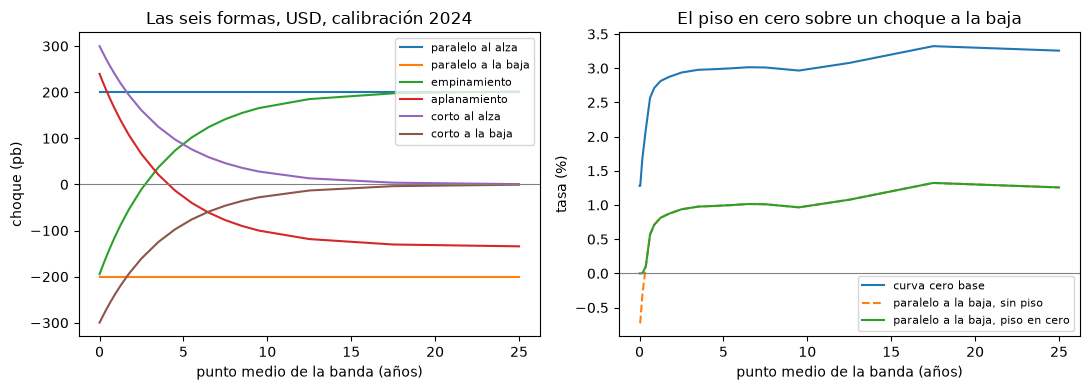

In [12]:
# Dibujar las seis formas y el efecto del piso en cero sobre el choque paralelo a la baja
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
for s in shocks.SHOCKS:
    left.plot(MID, shapes[s], label=NAME[s])
left.axhline(0, color="grey", linewidth=0.8)
left.set_xlabel("punto medio de la banda (años)")
left.set_ylabel("choque (pb)")
left.set_title("Las seis formas, USD, calibración 2024")
left.legend(fontsize=8)
right.plot(MID, r0 * 100, label="curva cero base")
right.plot(MID, raw * 100, linestyle="--", label="paralelo a la baja, sin piso")
right.plot(MID, floored * 100, label="paralelo a la baja, piso en cero")
right.axhline(0, color="grey", linewidth=0.8)
right.set_xlabel("punto medio de la banda (años)")
right.set_ylabel("tasa (%)")
right.set_title("El piso en cero sobre un choque a la baja")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Resultados

- **Los escalares y el ejemplo.** A 3,5 años el escalar corto es 0,4169 (el estándar imprime 0,417) y el largo 0,5831. Con tamaños de 100 pb el choque corto es 41,69 pb, el empinamiento +25,39 pb y el aplanamiento -1,64 pb, cada uno igual al cálculo a mano de la definición. La prueba `irrbb.srp31_92_goldens` es verde con desviaciones de 0,0001, 0,0138, 0,0136 y 0,0393 frente a las tolerancias de 0,0005 y 0,05; el aplanamiento es el más lejano del valor impreso porque el estándar redondea a un decimal (-1,6393 frente a -1,6). La compuerta es entonces "igual a la precisión impresa", no "igual hasta el último dígito", y la fila versionada guarda los mismos cuatro valores.
- **Los tamaños.** Para el USD solo se mueve el tamaño largo entre las calibraciones (150 pb en 2016, 225 pb en 2024); para el EUR se mueven los tres (200/250/100 a 225/350/200); el JPY no se mueve. Las dos tablas de Basilea tienen 21 monedas y ninguna tiene el peso, así que el motor rechaza un tamaño para él en vez de inventarlo; la tabla chilena da al peso 300/400/200 pb y a la UF 200/250/150 pb para el EVE, y un único choque paralelo de 300 pb para ambos en el NII. Un validador debe leer el origen de cada tamaño antes de leer cualquier resultado: dice de quién es el número.
- **Las formas.** Las seis formas del USD en 2024 son iguales a las versionadas. El empinamiento es la forma que más mueve la recalibración: su extremo largo es +134,36 pb con los tamaños de 2016 y +201,73 pb con los de 2024, porque el tamaño largo pasó de 150 a 225 pb. El aplanamiento, en cambio, es grande en el extremo corto (+239,74 pb en la banda 1) y negativo en el largo (-134,28 pb en la banda 19).
- **Los pisos.** Con la curva base del 2022-06-30 (1,28 por ciento en las primeras bandas) el piso en cero actúa en las bandas 1 a 3 bajo el choque paralelo a la baja y el empinamiento, y en las bandas 1 a 4 bajo el choque corto a la baja; nunca actúa bajo los choques al alza ni el aplanamiento, y las listas son iguales a las versionadas. En la banda 1 el choque paralelo a la baja daría -0,721 por ciento, que el piso devuelve a cero. El piso dependiente del plazo de la Unión Europea parte en -1,5 por ciento y actúa solo bajo el choque corto a la baja, en las bandas 1 y 2. El piso cambia la curva con choque, así que cambia todo delta EVE que la lee: los números versionados de los cuadernos siguientes ya lo incluyen.
- **Lo que el cuaderno no muestra.** Cómo llega una forma a los flujos para dar un cambio de EVE (cuadernos 03 y 06), los tamaños de los choques de NII más allá del único paralelo, y la calibración de los propios tamaños, que el estándar describe en SRP98 y el motor toma como datos.

## Resumen

- Las seis formas salen de dos escalares, $e^{-t/4}$ y su complemento, y tres tamaños por moneda: los choques paralelo y corto usan un escalar cada uno, y el empinamiento y el aplanamiento rotan con los pesos -0,65 y +0,9, y +0,8 y -0,6.
- El ejemplo del propio estándar, 0,417, +41,7 pb, +25,4 pb y -1,6 pb a 3,5 años, es una prueba de valores de referencia del motor, verde dentro de su tolerancia, y el aplanamiento es el valor más lejano del impreso.
- Los tamaños son una tabla: dos calibraciones de Basilea, 2016 y 2024, y la tabla chilena. Una moneda sin entrada se rechaza, y una estimación lleva su etiqueta y su método.
- Un piso nunca eleva una tasa por encima de su valor previo al choque; el piso en cero actúa en las bandas cortas de la curva del USD de mediados de 2022 bajo los choques a la baja, y el piso UE dependiente del plazo actúa solo bajo el choque corto a la baja, en dos bandas.
- Toda forma y toda lista de bandas recalculada aquí es igual a la versionada, calculada por la misma versión del motor.

**Qué probar a continuación.** Cambia el tamaño largo de `shock_curve` y mira cuál de las dos rotaciones se mueve más. Después sigue con el cuaderno 03, la capa de comportamiento.

## Referencias

- BCBS, Standards: Interest rate risk in the banking book, SRP31.90 a SRP31.93 (los seis choques, los tamaños y el piso) y SRP31.96 (las 19 bandas de tiempo). https://www.bis.org/basel_framework/chapter/SRP/31.htm
- BCBS (2016), d368, Standards: Interest rate risk in the banking book, Anexo 2, Tabla 1 (la calibración de 2016). https://www.bis.org/bcbs/publ/d368.htm
- BCBS (2024), d578, Recalibration of shocks for interest rate risk in the banking book (la calibración de 2024, vigente desde 2026-01-01). https://www.bis.org/publications/202407-standards-recalibration-shocks-interest-rate-risk-banking-book.pdf
- CMF, Recopilación Actualizada de Normas, capítulo 21-13, Anexo 1, hoja 9 (los tamaños de choque chilenos), según se transcriben en el motor y en el dossier 03, F.2.
- Reglamento Delegado (UE) 2024/856 de la Comisión, artículo 3(7) (el piso dependiente del plazo), según lo cita el motor. https://eur-lex.europa.eu/eli/reg_del/2024/856/oj/eng
- Dossier 01 de la investigación de Contraste (marco de Basilea), secciones H.2 a H.3.